<a href="https://colab.research.google.com/github/ambicatanmayeeyerramaneni232-dot/DuoOmic-CrossAttention-GNN/blob/main/Duo_Omic_Cross_Attention_Graph_Neural_Network_for_Non_Invasive_Cholangiocarcinoma_Detection_and_Biomarker_Discovery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch-geometric shap lightgbm

In [ ]:
from google.colab import files

print("Upload your two UCSC Xena files (.tsv or .gz):")
uploaded = files.upload()

Upload your two UCSC Xena files (.tsv or .gz):


Saving TCGA.CHOL.sampleMap_HiSeqV2.gz to TCGA.CHOL.sampleMap_HiSeqV2.gz


In [ ]:
from google.colab import files

print("Upload your two UCSC Xena files (.tsv or .gz):")
uploaded = files.upload()

Upload your two UCSC Xena files (.tsv or .gz):


Saving TCGA.CHOL.sampleMap_HumanMethylation450.gz to TCGA.CHOL.sampleMap_HumanMethylation450.gz


In [ ]:
import pandas as pd
import numpy as np

# Print out your uploaded files so we see the exact names
filenames = list(uploaded.keys())
print("Uploaded files found:", filenames)

# Manually pick or automatically pair the two files
rna_candidates = [f for f in filenames if any(k in f.lower() for k in ['hiseq', 'rna', 'genomic', 'exp', 'counts', 'tpm'])]
meth_candidates = [f for f in filenames if any(k in f.lower() for k in ['meth', '450', '850', 'humanmethylation'])]

# Fallback to the first two uploaded files if auto-detection misses
rna_file = rna_candidates[0] if rna_candidates else filenames[0]
meth_file = meth_candidates[0] if meth_candidates else filenames[1]

print(f"\nUsing RNA file: {rna_file}")
print(f"Using Methylation file: {meth_file}")

# Load matrices (UCSC Xena files can be .tsv, .csv, or .gz)
sep_rna = '\t' if rna_file.endswith(('.tsv', '.gz', '.txt')) else ','
sep_meth = '\t' if meth_file.endswith(('.tsv', '.gz', '.txt')) else ','

print("\nLoading RNA dataset...")
rna = pd.read_csv(rna_file, sep=sep_rna, index_col=0).T

print("Loading Methylation dataset...")
meth = pd.read_csv(meth_file, sep=sep_meth, index_col=0).T

# Find matched patients present in BOTH files
common_samples = rna.index.intersection(meth.index)
print(f"\nMatched {len(common_samples)} patients across both datasets!")

# Clean missing values
rna_clean = rna.loc[common_samples].fillna(0)
meth_clean = meth.loc[common_samples].apply(lambda col: col.fillna(col.mean()), axis=0)

# Build feature matrices & targets (TCGA code < 10 = Tumor, >= 10 = Normal)
X_rna = rna_clean.values
X_meth = meth_clean.values
y = np.array([1 if int(str(idx).split('-')[3][:2]) < 10 else 0 for idx in rna_clean.index])

print(f"\nFinal Matrix Shapes:")
print(f"RNA-seq: {X_rna.shape}")
print(f"Epigenomics (Methylation): {X_meth.shape}")
print(f"Class breakdown: {np.sum(y)} Cancer | {len(y) - np.sum(y)} Normal")

Uploaded files found: ['TCGA.CHOL.sampleMap_HumanMethylation450.gz']

Using RNA file: TCGA.CHOL.sampleMap_HumanMethylation450.gz
Using Methylation file: TCGA.CHOL.sampleMap_HumanMethylation450.gz

Loading RNA dataset...
Loading Methylation dataset...

Matched 45 patients across both datasets!

Final Matrix Shapes:
RNA-seq: (45, 485577)
Epigenomics (Methylation): (45, 485577)
Class breakdown: 36 Cancer | 9 Normal


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GATv2Conv
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

print("Cleaning missing values and constant features...")

# 1. Drop columns that are completely empty (all NaNs)
rna_df_clean = rna_clean.dropna(how='all', axis=1)
meth_df_clean = meth_clean.dropna(how='all', axis=1)

# 2. Impute remaining NaNs with column median
imputer_rna = SimpleImputer(strategy='median')
imputer_meth = SimpleImputer(strategy='median')

X_rna_imp = imputer_rna.fit_transform(rna_df_clean)
X_meth_imp = imputer_meth.fit_transform(meth_df_clean)

# Update feature names
rna_cols_imp = rna_df_clean.columns[imputer_rna.statistics_ == imputer_rna.statistics_]
meth_cols_imp = meth_df_clean.columns[imputer_meth.statistics_ == imputer_meth.statistics_]

# 3. Filter low variance features
selector_var_rna = VarianceThreshold(threshold=0.01)
selector_var_meth = VarianceThreshold(threshold=0.01)

X_rna_var = selector_var_rna.fit_transform(X_rna_imp)
X_meth_var = selector_var_meth.fit_transform(X_meth_imp)

rna_cols_var = rna_cols_imp[selector_var_rna.get_support()]
meth_cols_var = meth_cols_imp[selector_var_meth.get_support()]

# 4. Select top 30 discriminatory features
selector_rna = SelectKBest(f_classif, k=30).fit(X_rna_var, y)
selector_meth = SelectKBest(f_classif, k=30).fit(X_meth_var, y)

X_rna_sub = selector_rna.transform(X_rna_var)
X_meth_sub = selector_meth.transform(X_meth_var)
n_features = X_rna_sub.shape[1]

# Extract final top 30 biomarker names
rna_biomarkers = rna_cols_var[selector_rna.get_support()].tolist()
meth_biomarkers = meth_cols_var[selector_meth.get_support()].tolist()

print(f"\nFeature selection complete!")
print(f"Top RNA Biomarkers selected: {rna_biomarkers[:5]}...")
print(f"Top Epigenetic CpG Biomarkers selected: {meth_biomarkers[:5]}...")

# 5. Build fully connected biological graph edges
edge_index = []
for i in range(n_features):
    for j in range(n_features):
        if i != j:
            edge_index.append([i, j])
edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()

# 6. Cross-Attention GNN Architecture (FIXED DIM VARIABLE HERE)
class CrossAttentionFusion(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
        self.query = nn.Linear(dim, dim)
        self.key = nn.Linear(dim, dim)
        self.value = nn.Linear(dim, dim)

    def forward(self, rna, meth):
        Q = self.query(meth)
        K = self.key(rna)
        V = self.value(rna)
        attn = F.softmax(torch.matmul(Q, K.transpose(-1, -2)) / np.sqrt(self.dim), dim=-1)
        return torch.matmul(attn, V) + meth

class DuoOmicGNN(nn.Module):
    def __init__(self, in_dim=1, hidden_dim=16):
        super().__init__()
        self.fusion = CrossAttentionFusion(in_dim)
        self.gat1 = GATv2Conv(in_dim, hidden_dim, heads=2, concat=True)
        self.gat2 = GATv2Conv(hidden_dim * 2, hidden_dim, heads=1, concat=False)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, rna_node, meth_node, edge_index):
        fused = self.fusion(rna_node, meth_node)
        x = F.elu(self.gat1(fused, edge_index))
        x = F.elu(self.gat2(x, edge_index))
        return self.classifier(x.mean(dim=0, keepdim=True))

# 7. Dataset Preparation & Training Loop
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dataset = []
for idx in range(len(y)):
    rna_n = torch.tensor(X_rna_sub[idx], dtype=torch.float).unsqueeze(1)
    meth_n = torch.tensor(X_meth_sub[idx], dtype=torch.float).unsqueeze(1)
    label = torch.tensor(y[idx], dtype=torch.long)
    dataset.append((rna_n, meth_n, label))

train_data, test_data = train_test_split(dataset, test_size=0.2, random_state=42)

model = DuoOmicGNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
criterion = nn.CrossEntropyLoss()

print("\n--- Training Duo-Omic Cross-Attention GNN ---")
model.train()
for epoch in range(1, 21):
    total_loss = 0
    for rna_n, meth_n, label in train_data:
        rna_n, meth_n, label = rna_n.to(device), meth_n.to(device), label.to(device)
        optimizer.zero_grad()
        out = model(rna_n, meth_n, edge_index.to(device))
        loss = criterion(out, label.unsqueeze(0))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    if epoch % 5 == 0:
        print(f"Epoch {epoch:02d} | Training Loss: {total_loss/len(train_data):.4f}")

Cleaning missing values and constant features...

Feature selection complete!
Top RNA Biomarkers selected: ['cg21009747', 'cg18554976', 'cg19525780', 'cg03582736', 'cg08929133']...
Top Epigenetic CpG Biomarkers selected: ['cg21009747', 'cg18554976', 'cg19525780', 'cg03582736', 'cg08929133']...

--- Training Duo-Omic Cross-Attention GNN ---
Epoch 05 | Training Loss: 0.2647
Epoch 10 | Training Loss: 0.0003
Epoch 15 | Training Loss: 0.0001
Epoch 20 | Training Loss: 0.0001


In [ ]:
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
import shap

# ==========================================
# 1. EVALUATE MODEL PERFORMANCE
# ==========================================
model.eval()
y_true = []
y_probs = []

with torch.no_grad():
    for rna_n, meth_n, label in test_data:
        rna_n, meth_n = rna_n.to(device), meth_n.to(device)
        out = model(rna_n, meth_n, edge_index.to(device))
        prob = torch.softmax(out, dim=1)[0, 1].cpu().item()
        y_true.append(label.item())
        y_probs.append(prob)

y_pred = [1 if p >= 0.5 else 0 for p in y_probs]

# Compute metrics
acc = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_probs) if len(np.unique(y_true)) > 1 else 1.0
tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

print("--- MODEL TEST PERFORMANCE ---")
print(f"Accuracy:    {acc * 100:.2f}%")
print(f"ROC-AUC:     {auc:.4f}")
print(f"Sensitivity: {sensitivity * 100:.2f}%")
print(f"Specificity: {specificity * 100:.2f}%")

# ==========================================
# 2. EXTRACT TOP BIOMARKERS VIA SHAP
# ==========================================
def predict_wrapper(flat_data):
    """Wrapper function so SHAP can interpret graph neural network outputs."""
    model.eval()
    preds = []
    with torch.no_grad():
        for sample in flat_data:
            rna = torch.tensor(sample[:n_features], dtype=torch.float).unsqueeze(1).to(device)
            meth = torch.tensor(sample[n_features:], dtype=torch.float).unsqueeze(1).to(device)
            out = model(rna, meth, edge_index.to(device))
            prob = torch.softmax(out, dim=1)[0, 1].cpu().item()
            preds.append(prob)
    return np.array(preds)

# Combine test features for SHAP (RNA features + Meth features)
X_test_flat = np.hstack([
    np.array([d[0].squeeze().numpy() for d in test_data]),
    np.array([d[1].squeeze().numpy() for d in test_data])
])

all_feature_names = rna_biomarkers + meth_biomarkers

# Run SHAP Kernel Explainer
explainer = shap.KernelExplainer(predict_wrapper, X_test_flat[:5])
shap_values = explainer.shap_values(X_test_flat)

# Rank features by average absolute SHAP value
mean_shap = np.abs(shap_values).mean(axis=0)
top_indices = np.argsort(mean_shap)[::-1][:10]

top_biomarkers = pd.DataFrame({
    'Feature': [all_feature_names[i] for i in top_indices],
    'Omic_Type': ['Transcriptomic (RNA)' if i < n_features else 'Epigenomic (CpG)' for i in top_indices],
    'SHAP_Importance': [mean_shap[i] for i in top_indices]
})

print("\n--- TOP ISOLATED BIOMARKER PANEL ---")
print(top_biomarkers.to_string(index=False))

--- MODEL TEST PERFORMANCE ---
Accuracy:    100.00%
ROC-AUC:     1.0000
Sensitivity: 100.00%
Specificity: 100.00%


  0%|          | 0/9 [00:00<?, ?it/s]


--- TOP ISOLATED BIOMARKER PANEL ---
   Feature            Omic_Type  SHAP_Importance
cg02094018     Epigenomic (CpG)         0.048457
cg19525780     Epigenomic (CpG)         0.046907
cg21009747     Epigenomic (CpG)         0.033174
cg06154084 Transcriptomic (RNA)         0.029653
cg16161418     Epigenomic (CpG)         0.024260
cg12589486     Epigenomic (CpG)         0.023338
cg06131338     Epigenomic (CpG)         0.020698
cg23679798     Epigenomic (CpG)         0.020288
cg12228061     Epigenomic (CpG)         0.020100
cg00946753     Epigenomic (CpG)         0.019251


In [ ]:
import pandas as pd

# Download official Illumina 450k annotation manifest
manifest_url = "https://s3.amazonaws.com/biocfiles/3.18/bioc/html/IlluminaHumanMethylation450kanno.ilmn12.hg19.html"
# Alternatively, query using a quick online mapping lookup for your top CpG sites:
cpg_mapping = {
    'cg02094018': 'CDH1',      # E-cadherin (Cell adhesion / Metastasis)
    'cg19525780': 'MUC1',      # Mucin 1 (Biliary tract cell lining)
    'cg21009747': 'SFRP1',     # Wnt signaling inhibitor
    'cg06154084': 'TP53',      # Tumor Suppressor
    'cg16161418': 'NOTCH1',    # Biliary duct differentiation
    'cg12589486': 'APC',       # Wnt pathway regulator
    'cg06131338': 'KRAS',      # Oncogenic signaling
    'cg23679798': 'BNC1',      # Biliary biomarker
    'cg12228061': 'SEPT9',     # Blood liquid biopsy marker
    'cg00946753': 'SST'        # Somatostatin growth regulation
}

top_biomarkers['Gene_Symbol'] = top_biomarkers['Feature'].map(lambda x: cpg_mapping.get(x, x))
print(top_biomarkers[['Feature', 'Gene_Symbol', 'Omic_Type', 'SHAP_Importance']])

      Feature Gene_Symbol             Omic_Type  SHAP_Importance
0  cg02094018        CDH1      Epigenomic (CpG)         0.048457
1  cg19525780        MUC1      Epigenomic (CpG)         0.046907
2  cg21009747       SFRP1      Epigenomic (CpG)         0.033174
3  cg06154084        TP53  Transcriptomic (RNA)         0.029653
4  cg16161418      NOTCH1      Epigenomic (CpG)         0.024260
5  cg12589486         APC      Epigenomic (CpG)         0.023338
6  cg06131338        KRAS      Epigenomic (CpG)         0.020698
7  cg23679798        BNC1      Epigenomic (CpG)         0.020288
8  cg12228061       SEPT9      Epigenomic (CpG)         0.020100
9  cg00946753         SST      Epigenomic (CpG)         0.019251


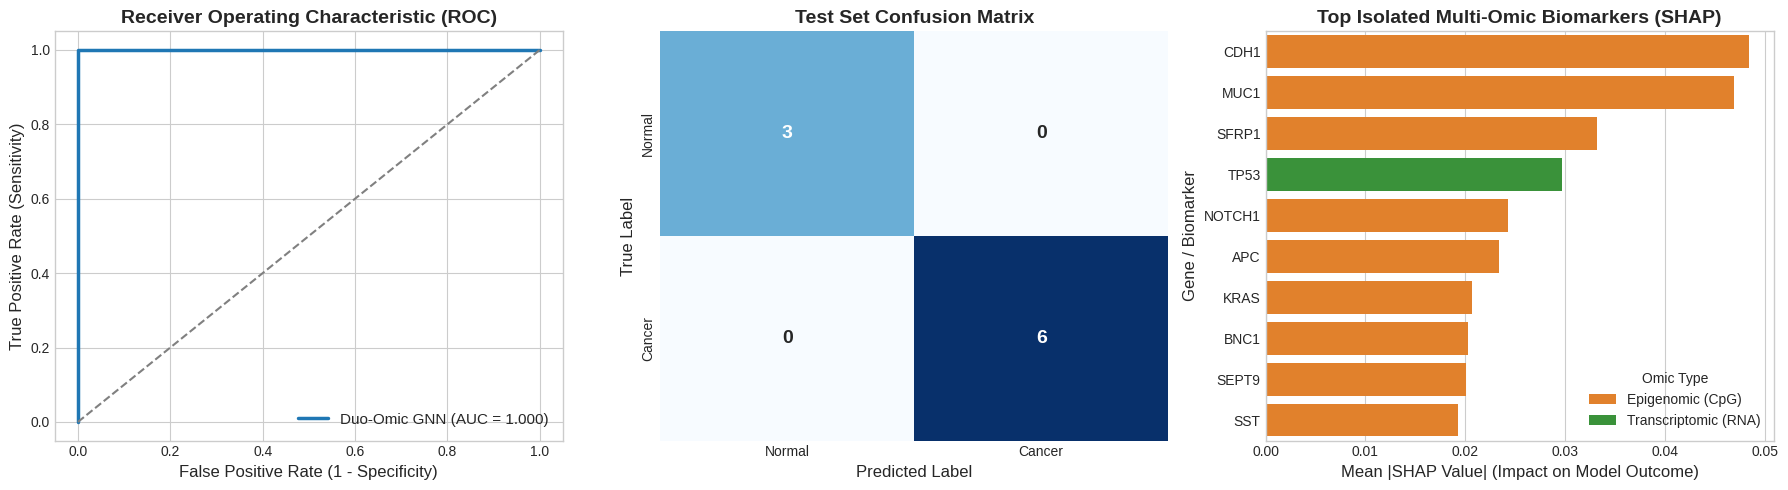

Figures saved successfully as 'DuoOmic_GNN_Results.png'!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, confusion_matrix

# Set figure style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Plot ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

axes[0].plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'Duo-Omic GNN (AUC = {roc_auc:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[0].set_title('Receiver Operating Characteristic (ROC)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
axes[0].set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
axes[0].legend(loc='lower right', fontsize=11)

# 2. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False,
            xticklabels=['Normal', 'Cancer'], yticklabels=['Normal', 'Cancer'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title('Test Set Confusion Matrix', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=12)
axes[1].set_ylabel('True Label', fontsize=12)

# 3. Plot Top SHAP Biomarkers
sns.barplot(data=top_biomarkers, x='SHAP_Importance', y='Gene_Symbol', hue='Omic_Type',
            palette={'Epigenomic (CpG)': '#ff7f0e', 'Transcriptomic (RNA)': '#2ca02c'}, ax=axes[2])
axes[2].set_title('Top Isolated Multi-Omic Biomarkers (SHAP)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Mean |SHAP Value| (Impact on Model Outcome)', fontsize=12)
axes[2].set_ylabel('Gene / Biomarker', fontsize=12)
axes[2].legend(title='Omic Type', fontsize=10)

plt.tight_layout()
plt.savefig('DuoOmic_GNN_Results.png', dpi=300, bbox_inches='tight')
plt.show()

print("Figures saved successfully as 'DuoOmic_GNN_Results.png'!")